In [57]:
from langgraph.graph import StateGraph,START,END
from langchain_groq import ChatGroq
from typing import TypedDict,Annotated,List,Optional
from pydantic import BaseModel,Field
from dotenv import load_dotenv
from langchain_core.messages import SystemMessage,HumanMessage
from tavily import TavilyClient
import os
import operator
import pathlib
import subprocess
from langchain_core.tools import tool
from langgraph.prebuilt import create_react_agent
from langchain_openai import ChatOpenAI
from langchain_openrouter import ChatOpenRouter
load_dotenv(override=True)
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_PROJECT"] = "SDLC-Agent-Analysis"
if not os.getenv("LANGSMITH_API_KEY"):
    raise ValueError("LANGSMITH_API_KEY is missing from .env")

In [ ]:
gptoss=ChatGroq(model="openai/gpt-oss-120b",api_key=os.getenv("groq1"))
qween=ChatGroq(model="qwen/qwen3.8-27b",api_key=os.getenv("groq2"),max_tokens=8000)
# boss_model = ChatOpenRouter(
#     model="nvidia/nemotron-3-ultra-550b-a55b:free",
#     temperature=0,
# )
boss_model = ChatOpenAI(model="gpt-6-luna")

In [59]:
class PlanningSchema(BaseModel):
    idea: str = Field(description="The initial app or project idea from the user")

class AnalysisSchema(BaseModel):
    user_requirement: str = Field(description="Extracted requirements based on the idea")
    internet_search_query: str = Field(description="Search query generated from the idea and requirements")

class File(BaseModel):
    path: str = Field(description="The path to the file to be created or modified")
    purpose: str = Field(description="The purpose of the file, e.g. 'main application logic'")

class DesigningSchema(BaseModel):
    name: str = Field(description="The name of the app to be built")
    description: str = Field(description="A one-line description of the app to be built")
    techstack: str = Field(description="The tech stack to be used, e.g. 'python, react, flask'")
    features: List[str] = Field(description="A list of features that the app should have")
    files: List[File] = Field(description="A list of files to be created, each with a 'path' and 'purpose'")

class ImplementationTask(BaseModel):
    filepath: str = Field(description="The path to the file to be modified")
    task_description: str = Field(description="A detailed description of the task to be performed on the file")

class TestBug(BaseModel):
    filepath: str = Field(description="The file path where the bug or error occurred")
    error_message: str = Field(description="The exact error message or traceback found during testing")
    fix_applied: str = Field(description="Description of the fix applied to resolve the issue")

class TestingSchema(BaseModel):
    tests_passed: bool = Field(description="True if all builds, imports, and functional tests passed without errors")
    test_commands_run: List[str] = Field(default_factory=list, description="List of shell/test commands executed (e.g. 'pytest', 'npm run build')")
    bugs_found: List[TestBug] = Field(default_factory=list, description="List of bugs discovered and fixed during the testing run")
    summary: str = Field(description="Overall summary of test coverage and final verification results")

class AI_Agent_State(TypedDict):
    user_prompt:str
    idea: str
    plan: PlanningSchema
    analysis: AnalysisSchema
    search_results: str
    design: DesigningSchema
    tasks: List[ImplementationTask]
    current_step_idx: int
    status: str
    completed_files: Annotated[List[str], operator.add]
    test_attempts: int
    test_results: Optional[TestingSchema]

In [60]:
planning_system_prompt="""You are an expert Product Manager and Software Strategist. Your job is to take a raw, potentially vague user request and distill it into a clear, actionable software project idea.

### Instructions:
1. Identify the core problem the user wants to solve and the primary goal of the application.
2. Clarify the target audience and main value proposition in plain, concise language.
3. Keep the scope realistic for an initial build (MVP) while preserving the user's original intent.
4. Do not invent unnecessary complex features or specify low-level code details yet.

### Output Format:
Respond strictly matching the requested schema, populating the `idea` field with a clear, well-structured summary of the app concept.
"""
def Planning_phase(Mainstate:AI_Agent_State) ->dict:
    user_main_prompt=Mainstate.get('user_prompt',"")
    res=qween.with_structured_output(PlanningSchema).invoke([SystemMessage(content=planning_system_prompt),HumanMessage(content=user_main_prompt)])
    return {'idea': res.idea,'plan':res}

In [61]:
Analysis_system_prompt="""You are a Senior Systems Analyst and Technical Researcher. Given a core project idea, your job is to break down what the user actually needs and formulate a targeted internet search query to gather technical context, best practices, or required APIs.
### Instructions:
1. **User Requirements (`user_requirement`):**
   - Translate the project idea into clear functional requirements (what the app must do) and non-functional requirements (performance, usability, or data needs).
   - List core user flows, necessary inputs/outputs, and edge cases to consider.
   - Keep the requirements specific, unambiguous, and ready for a software architect to design around.
2. **Internet Search Query (`internet_search_query`):**
   - Generate a single, high-signal search engine query based on the idea and extracted requirements.
   - Focus the query on finding modern tech stack recommendations, open-source libraries, APIs, or architectural patterns relevant to building this specific app.
   - Avoid conversational filler words; write it like an effective Google/Tavily search string (e.g., "best python library for real-time audio transcription architecture 2026").
### Output Format:
Respond strictly matching the requested schema, accurately filling both `user_requirement` and `internet_search_query`.
"""
client = TavilyClient(
    api_key=os.environ["TAVILY_API_KEY"]
)
def Analysis_phase(Mainstate: AI_Agent_State) -> dict:
    idea = Mainstate.get('idea', "")
    res = qween.with_structured_output(AnalysisSchema).invoke([SystemMessage(content=Analysis_system_prompt),HumanMessage(content=idea)])
    query = res.internet_search_query
    response = client.search(query=query, max_results=5)
    all_results = []
    for r in response.get("results", []):
        all_results.append(f"Query: {query}\nSource: {r['url']}\nContent: {r['content']}")
    return {"search_results": "\n\n---\n\n".join(all_results),"analysis": res}

In [62]:
designing_system_prompt = """You are a Principal Software Architect. Your job is to design a complete, production-ready software architecture based on the project idea, extracted user requirements, and technical research results.

### Instructions:
1. **App Identity (`name` & `description`):**
   - Choose a clean, memorable, and relevant name for the application (`name`).
   - Write a crisp, one-line summary explaining what the app does (`description`).

2. **Tech Stack (`techstack`):**
   - Select a modern, cohesive, and practical tech stack informed by the research context (e.g., "Python, FastAPI, React, TailwindCSS, SQLite").
   - Ensure all chosen technologies work smoothly together and fit the scope of the project.

3. **Core Features (`features`):**
   - List clear, concrete features that directly fulfill the `user_requirement`.
   - Keep each feature focused on actionable functionality rather than vague goals.

4. **Project File Structure (`files`):**
   - Design a clean, modular folder and file structure ready for implementation.
   - Include configuration files (e.g., `requirements.txt`, `package.json`, `.env.example`), backend/core logic files, frontend/UI files (if applicable), and a clear entry point (e.g., `main.py` or `app.py`).
   - For every file, provide an exact relative `path` and a detailed `purpose` explaining what code belongs inside it and how it connects to other files.

### Output Format:
Respond strictly matching the requested schema, accurately populating `name`, `description`, `techstack`, `features`, and `files`.
"""

def Designing_phase(Mainstate:AI_Agent_State)->dict:
    internet_search_result=Mainstate['search_results']
    analysis_output=Mainstate['analysis']
    human_content = (
        f"User Requirements:\n{analysis_output.user_requirement}\n\n"
        f"Internet Search Results:\n{internet_search_result}"
    )
    design=gptoss.with_structured_output(DesigningSchema).invoke([SystemMessage(content=designing_system_prompt),HumanMessage(content=human_content)])
    return {'design':design}

In [63]:
PROJECT_ROOT = pathlib.Path.cwd() / "generated_project"
def init_project_root():
    PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
    return str(PROJECT_ROOT)

def safe_path_for_project(path: str) -> pathlib.Path:
    p = (PROJECT_ROOT / path).resolve()
    if PROJECT_ROOT.resolve() not in p.parents and PROJECT_ROOT.resolve() != p.parent and PROJECT_ROOT.resolve() != p:
        raise ValueError("Attempt to write outside project root")
    return p

@tool
def write_file(path: str, content: str) -> str:
    """Writes content to a file at the specified path within the project root."""
    p = safe_path_for_project(path)
    p.parent.mkdir(parents=True, exist_ok=True)
    with open(p, "w", encoding="utf-8") as f:
        f.write(content)
    return f"WROTE:{p}"

@tool
def read_file(path: str) -> str:
    """Reads content from a file at the specified path within the project root."""
    p = safe_path_for_project(path)
    if not p.exists():
        return ""
    with open(p, "r", encoding="utf-8") as f:
        return f.read()

@tool
def get_current_directory() -> str:
    """Returns the current working directory."""
    return str(PROJECT_ROOT)

@tool
def list_files(directory: str = ".") -> str:
    """Lists all files in the specified directory within the project root."""
    p = safe_path_for_project(directory)
    if not p.is_dir():
        return f"ERROR: {p} is not a directory"
    files = [str(f.relative_to(PROJECT_ROOT)) for f in p.glob("**/*") if f.is_file()]
    return "\n".join(files) if files else "No files found."

coder_system_prompt = """You are an expert Full-Stack Software Engineer. Your job is to implement complete, bug-free, production-ready code for a specific file in a software project.
### Instructions:
1. Review the overall application design, tech stack, features, and full file tree to ensure imports, API routes, and function signatures match across files.
2. Check existing files using `read_file` or `list_files` if you need to verify exact variable names or exports from previously written files.
3. Write clean, modular, well-documented code with proper error handling. Never leave placeholders, TODOs, or incomplete snippets.
4. Always use the `write_file(path, content)` tool to save the complete file content.
"""

In [64]:
def Implementation_phase(Mainstate: AI_Agent_State) -> dict:
    """LangGraph tool-using coder node aligned with AI_Agent_State."""
    init_project_root()
    design = Mainstate["design"]
    files = design.files
    step_idx = Mainstate.get("current_step_idx", 0)
    if step_idx >= len(files):
        return {"status": "DONE"}
    current_file = files[step_idx]
    existing_content = read_file.run(current_file.path)
    file_tree = "\n".join([f"- {f.path}: {f.purpose}" for f in files])
    user_prompt = (
        f"### Application Overview:\n"
        f"Name: {design.name}\n"
        f"Description: {design.description}\n"
        f"Tech Stack: {design.techstack}\n"
        f"Features: {', '.join(design.features)}\n\n"
        f"### Full Project File Structure:\n{file_tree}\n\n"
        f"### Current Task:\n"
        f"Target File: {current_file.path}\n"
        f"File Purpose: {current_file.purpose}\n"
        f"Existing Content:\n{existing_content if existing_content else 'Empty (New File)'}\n\n"
        f"Implement the full code for `{current_file.path}` and save it using `write_file(path, content)`."
    )

    coder_tools = [read_file, write_file, list_files, get_current_directory]
    react_agent = create_react_agent(boss_model, coder_tools)

    react_agent.invoke({
        "messages": [
            {"role": "system", "content": coder_system_prompt},
            {"role": "user", "content": user_prompt}
        ]
    })
    return {
        "current_step_idx": step_idx + 1,
        "completed_files": [current_file.path],
        "status": "IN_PROGRESS"
    }

In [65]:
@tool
def run_command(command:str)->dict:
    """Executes a shell command inside the project root and returns stdout/stderr."""
    garbage_command=["rm -rf","sudo","mkfs","shutdown","reboot"]
    if any(bad in command for bad in garbage_command):
        return "ERROR: command blocked for safety reasons."
    try:
        test_result=subprocess.run(command,shell=True,cwd=str(PROJECT_ROOT),capture_output=True,text=True,timeout=60)
        output=(f"Exit code:{test_result.returncode}\n"
                f"Command executed:{command}\n"
                f"Status:{'Success' if test_result.returncode == 0 else 'failed'}\n")
        max_chars = 4000
        stdout = test_result.stdout[-max_chars:] if test_result.stdout else ""
        stderr = test_result.stderr[-max_chars:] if test_result.stderr else ""
        if stdout:
            output+=f"STDOUT:\n{stdout}\n"
        if stderr:
            output+=f":\n{stderr}\n"
        return output
    except subprocess.TimeoutExpired:
        return(
            f"Command executed:{command}\n"
            f"Exit code:124\n"
            f"Status:Failed\n"
            f"STDERR:\nError:Command timed out after 60 seconds."
            f"(Tip: Do not start blocking servers like 'npm start' or 'uvicorn' directly; use test clients instead.)"
        )
    except Exception as e:
        return (
            f"Command excecuted:{command}\n"
            f"Exite code:1\n"
            f"Statue : Failed\n"
            f"Stderr : \nError:{str(e)}")

In [66]:
tester_system_prompt = """You are an expert QA Automation & Full-Stack Debugging Engineer.
Your job is to verify that the generated project builds, runs, and passes functional tests without errors.

### Instructions:
1. Inspect the project structure using `list_files` and `read_file`.
2. Install required dependencies if needed (e.g., `pip install -r requirements.txt` or `npm install`).
3. Write automated tests (e.g., `pytest` for Python backends, `jest`/build checks for frontends) using `write_file`.
4. Run the tests and build checks using `run_command`.
   - **Important**: Never run blocking commands like `npm start` or `uvicorn` directly unless you run them in the background and kill them, or test via a test client (like FastAPI's `TestClient`).
5. If ANY test or build fails:
   - Read the error traceback carefully.
   - Fix the buggy source file using `write_file`.
   - Re-run `run_command` to verify the fix.
6. Once all tests pass, conclude with a clear summary stating: "ALL TESTS PASSED".
"""
def Testing_phase(Mainstate:AI_Agent_State)->dict:
    init_project_root()
    design = Mainstate['design']
    test_attempts = Mainstate.get("test_attempts",0)
    if test_attempts >= 3:
        return {"status":"Failed_max_retries"}
    file_tree=list_files.run(".")
    user_prompt=(
        f"""
            App Name:{design.name}\n
            Tech Stack:{design.techstack}\n
            Feature:{','.join(design.features)}
            Files:\n{file_tree}\n\n
            Install dependecies,write tests,run them with 'run_command', and fix any bugs found."""
    )
    tester_tools=[read_file,write_file,list_files,get_current_directory,run_command]
    qa_agent =create_react_agent(boss_model,tester_tools)
    agent_output=qa_agent.invoke({
        "messages":[
            {"role":"system","content":tester_system_prompt},
            {"role":"user","content":user_prompt}
        ]
    })
    tool_logs = "\n---\n".join(
        msg.content for msg in agent_output["messages"] if msg.type == "tool"
    )
    structured_llm=boss_model.with_structured_output(TestingSchema)
    test_report=structured_llm.invoke(f"Summarize the following QA testing session into the required schema:\n\n"
                                      f"Tool Execution Logs:\n{tool_logs}\n\n"
                                      f"{agent_output['messages'][-1].content}")
    return {
        "test_attempts": test_attempts +1,
        "test_results": test_report,
        "status":"Test_passed" if test_report.tests_passed else "Test_failed"
    }

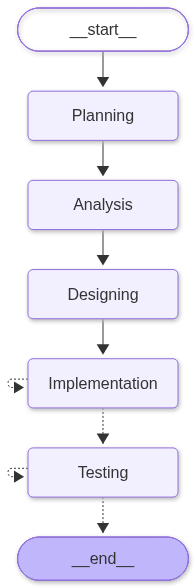

In [67]:
def route_implementation(state: AI_Agent_State):
    if state.get("status") == "DONE":
        return "Testing"
    return "Implementation"

def route_testing(state: AI_Agent_State):
    if state.get("status") in ["Test_passed", "Failed_max_retries"]:
        return END
    return "Testing"
Agent=StateGraph(AI_Agent_State)
Agent.add_node("Planning",Planning_phase)
Agent.add_node("Analysis",Analysis_phase)
Agent.add_node("Designing",Designing_phase)
Agent.add_node("Implementation",Implementation_phase)
Agent.add_node("Testing",Testing_phase)

Agent.add_edge(START,"Planning")
Agent.add_edge("Planning","Analysis")
Agent.add_edge("Analysis","Designing")
Agent.add_edge("Designing","Implementation")
Agent.add_conditional_edges("Implementation", route_implementation,{"Implementation": "Implementation","Testing": "Testing"})
Agent.add_conditional_edges("Testing", route_testing,{"Testing": "Testing",END: END})
SDLC_Agent=Agent.compile()
SDLC_Agent

In [68]:
initial_state = {
    "user_prompt": "Build a full-stack Task Manager web app with FastAPI and HTML/JS",
    "current_step_idx": 0,
    "completed_files": [],
    "test_attempts": 0,
    "status": "STARTED"
}
result = SDLC_Agent.invoke(initial_state,config={"recursion_limit": 100,"run_name": "SDLC-Agent-Execution","tags": ["SDLC","LangGraph","Multi-Agent","Code-Generation"],"metadata": {"agent_version": "1.0","project_type": "Full-Stack Development","environment": "development"}})

C:\Users\jay\AppData\Local\Temp\ipykernel_10680\2625941025.py:27: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  react_agent = create_react_agent(boss_model, coder_tools)
C:\Users\jay\AppData\Local\Temp\ipykernel_10680\2596493764.py:32: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  qa_agent =create_react_agent(boss_model,tester_tools)
